# 16 · Freeway Traffic Incident Detection (PeMS, IEEE DataPort)

**Utility for the City Brain: low** · Domain: traffic · Incident types: `accident`, `traffic_jam`

> Freeway detector windows at incident times and the same detectors on normal days. Expected to measure how many incidents our rules catch; in practice incident and normal windows look the same.

| | |
|---|---|
| **Source** | IEEE DataPort, *Freeway Traffic Incident Detection Dataset*, DOI 10.21227/hcxe-7k08 (Caltrans PeMS, 2023) |
| **Licence** | IEEE DataPort terms: not redistributed here |
| **In this repo** | No data. Outputs below were produced on the full download |
| **Get it** | IEEE DataPort (account needed): `incident_data.parquet` (146 MB), `non_incident_data.parquet` (293 MB) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside (worked out from the data: no documentation in the files)

Columns `Time, Data1…Data25, tag, Week, Percentage, Median, Hour, Month, Day, Y`. Each row = **25 consecutive readings** of one variable at one detector. Rows come in **groups of three**: occupancy (0–1), speed (mph), flow. `Median` = the detector's usual value at that time (baseline). `Y = 1` in the incident file; the normal file has the same detectors **the day before and after**.

In [2]:
D = [f'Data{i}' for i in range(1, 26)]
def triplets(f):
    d = pd.read_parquet(path(f'traffic/ieee-freeway-incidents/{f}')).reset_index(drop=True)
    X = d[D].to_numpy(); mx = np.nanmax(np.nan_to_num(X, nan=-1), axis=1); n = len(d)
    i = np.where(mx <= 1)[0]; i = i[i < n - 2]
    i = i[(mx[i + 1] > 1) & (mx[i + 1] <= 100) & (mx[i + 2] > 1) & (d.Day.values[i] == d.Day.values[i + 1])]
    out = dict(rows=n, O=X[i], V=X[i + 1], F=X[i + 2], med=d.Median.values[i + 1])
    print(f"{f}: {n:,} rows -> {len(i):,} detector windows"); del d
    return out
inc, nor = triplets('incident_data.parquet'), triplets('non_incident_data.parquet')

incident_data.parquet: 3,269,021 rows -> 929,689 detector windows


non_incident_data.parquet: 6,535,691 rows -> 1,848,610 detector windows


## 2. Data problems: duplicates and overlap

In [3]:
def key(t): return pd.util.hash_pandas_object(pd.DataFrame(np.round(np.nan_to_num(np.hstack([t['O'], t['V'], t['F']]), nan=-9), 3)), index=False).to_numpy()
ki, kn = key(inc), key(nor)
print(f"Duplicate windows: incident {pd.Series(ki).duplicated().mean() * 100:.0f} %, normal {pd.Series(kn).duplicated().mean() * 100:.0f} %")
in_normal = np.isin(ki, kn)
print(f"Incident windows that also appear in the normal file: {in_normal.mean() * 100:.0f} %")
keep_i = (~pd.Series(ki).duplicated().to_numpy()) & ~in_normal
keep_n = ~pd.Series(kn).duplicated().to_numpy()
print(f"Clean: {keep_i.sum():,} incident and {keep_n.sum():,} normal windows")

Duplicate windows: incident 59 %, normal 61 %


Incident windows that also appear in the normal file: 18 %
Clean: 345,863 incident and 727,657 normal windows


## 3. Our jam rule on incident vs normal windows

In [4]:
def runs(b, k=3):
    run = np.zeros(len(b)); out = np.zeros(len(b), bool)
    for j in range(b.shape[1]): run = np.where(b[:, j], run + 1, 0); out |= run >= k
    return out
def rates(t, keep):
    O, V, F, med = t['O'][keep], t['V'][keep], t['F'][keep], t['med'][keep]
    r = V / np.where(med > 0, med, np.nan)[:, None]
    return {'speed < 50 % of Median': runs((r < .5) & (F > 0)).mean(),
            '  + occupancy >= 25 %': runs((r < .5) & (O >= .25) & (F > 0)).mean(),
            'speed < 70 % of Median': runs((r < .7) & (F > 0)).mean(),
            'speed < 20 mph at any point': (np.nanmin(V, axis=1) < 20).mean()}
t = pd.DataFrame({'incident windows': rates(inc, keep_i), 'normal windows': rates(nor, keep_n)})
t['ratio'] = t['incident windows'] / t['normal windows']
(t.assign(**{c: t[c] * 100 for c in ['incident windows', 'normal windows']})).round(2)   # % of windows

,incident windows,normal windows,ratio
speed < 50 % of Median,2.59,2.79,0.93
+ occupancy >= 25 %,1.47,1.61,0.91
speed < 70 % of Median,6.64,6.70,0.99
speed < 20 mph at any point,3.80,3.23,1.17


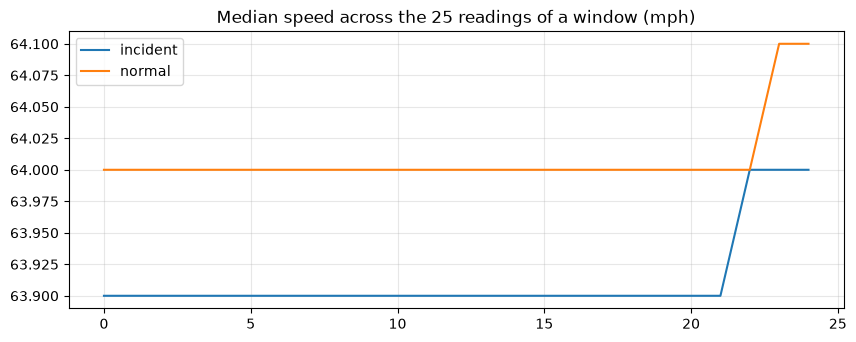

In [5]:
plt.plot(np.nanmedian(inc['V'][keep_i], axis=0), label='incident'); plt.plot(np.nanmedian(nor['V'][keep_n], axis=0), label='normal')
plt.title('Median speed across the 25 readings of a window (mph)'); plt.legend(); plt.show()

**Incident and normal windows are statistically the same.** Most logged freeway incidents (minor crashes, debris, stalled cars) don't slow traffic at a given detector, or the detector isn't the one next to the incident.

## 4. What it means for the City Brain

| Use | How |
|---|---|
| **Detect** | Confirms: **one traffic sensor is not evidence of an accident**. `accident` needs a call, or several neighbouring sensors + persistence |
| **Eval** | Freeway false-alarm ceiling: the jam rule without the neighbour condition fires on ~1.6 % of normal 2-hour windows; the "≥ 2 neighbours" condition is mandatory |
| **Not usable for** | Measuring recall. For that we need incidents with exact place and start time (TraffiDent on Kaggle, `gpxlcj/xtraffic`) or our own labelled Storm-night scenario |

**Limits:** ~60 % duplicates; `Time` stored as 32-bit float (unusable as a timestamp); `tag` and `Percentage` undocumented.